# Исправленный код экспериментов (вариант B): CBIS-DDSM
Ячейки выполняются строго по порядку. Описание шагов, список исправленных ошибок и что присылать — в сопроводительном документе Word.

## Шаг 0. Подготовка
Подключение Google Drive. Вне Colab ячейка ничего не делает.

In [1]:
# Шаг 0. Подключение Google Drive
try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    pass  # запуск не в Colab

Mounted at /content/drive


In [2]:
# Шаг 0. Библиотеки, пути, устройство
import os, glob, json, random, time, copy, hashlib
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from collections import Counter
from PIL import Image
from tqdm.auto import tqdm
import torch, torch.nn as nn, torch.nn.functional as F
import torchvision, sklearn
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms
from sklearn.model_selection import StratifiedGroupKFold, StratifiedKFold
from sklearn.metrics import roc_auc_score, roc_curve

BASE_DIR = "/content/drive/MyDrive/Докторантура/Исследования/New_research_april/CBIS"
JPEG_DIR = f"{BASE_DIR}/jpeg"
OUT_DIR  = f"{BASE_DIR}/revision_v2"        # новая папка: старые файлы не трогаем
RUN_DIR, FIG_DIR, TAB_DIR, W_DIR = (f"{OUT_DIR}/{d}" for d in
                                    ("runs", "figures", "tables", "weights"))
for d in (RUN_DIR, FIG_DIR, TAB_DIR, W_DIR):
    os.makedirs(d, exist_ok=True)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device, "| torch", torch.__version__, "| torchvision",
      torchvision.__version__, "| sklearn", sklearn.__version__)
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

device: cuda | torch 2.14.1+cu130 | torchvision 0.29.1+cu130 | sklearn 1.6.1
GPU: Tesla T4


**Что проверить:** Должно быть: device: cuda и название GPU. Если device: cpu, включите GPU (Runtime → Change runtime type) и начните с этой ячейки заново.

In [3]:
# Шаг 0. Все гиперпараметры в одном месте (их нужно привести в статье, R1.3 / R2.2)
CONFIG = dict(
    IMG_SIZE=224,       # размер входа сети
    BATCH_SIZE=32,
    MAX_EPOCHS=30,      # максимум эпох (в исходной версии было 5)
    MIN_EPOCHS=5,
    PATIENCE=7,         # early stopping по AUC на валидации
    LR_HEAD=1e-3,       # классификационная голова ResNet50
    LR_BACKBONE=1e-4,   # размороженные блоки ResNet50
    LR_SCRATCH=1e-3,    # CNN, обучаемые с нуля
    WEIGHT_DECAY=1e-4,
    N_FOLDS=5,          # внешняя кросс-валидация по пациентам
    SPLIT_SEED=42,
    TRAIN_SEEDS=[0],    # для повторов инициализации можно поставить [0, 1, 2]
    N_BOOT=2000,        # число бутстреп-выборок для доверительных интервалов
    NUM_WORKERS=2,
    USE_AMP=True,       # смешанная точность на GPU
    PRETRAINED=True,    # веса ImageNet (IMAGENET1K_V1)
    MASK_THR=0.98,      # порог для отличия бинарной маски от кропа (Шаг 2)
)
C = CONFIG

def set_seed(seed):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(C["SPLIT_SEED"])
hp = pd.DataFrame({"parameter": list(C.keys()), "value": [str(v) for v in C.values()]})
hp.to_csv(f"{TAB_DIR}/table_hyperparameters.csv", index=False)
print(hp.to_string(index=False))

   parameter  value
    IMG_SIZE    224
  BATCH_SIZE     32
  MAX_EPOCHS     30
  MIN_EPOCHS      5
    PATIENCE      7
     LR_HEAD  0.001
 LR_BACKBONE 0.0001
  LR_SCRATCH  0.001
WEIGHT_DECAY 0.0001
     N_FOLDS      5
  SPLIT_SEED     42
 TRAIN_SEEDS    [0]
      N_BOOT   2000
 NUM_WORKERS      2
     USE_AMP   True
  PRETRAINED   True
    MASK_THR   0.98


**Что проверить:** Таблица гиперпараметров сохраняется в tables/table_hyperparameters.csv; её нужно привести в статье. Значения можно менять только здесь и только до запуска шага 6, иначе результаты разных запусков будут несопоставимы. Дополнительно в статье нужно указать: оптимизатор AdamW, косинусное расписание, голова ResNet (256 нейронов, ReLU, Dropout 0,3), аугментации (отражения, поворот ±15°, сдвиг 5%, масштаб 0,9–1,1, яркость и контраст 0,2).

## Шаг 1. Данные: CSV и бинарные метки
Загрузка CSV, объединение train и test, метки 0 и 1. Пробелы и переводы строк в путях удаляются.

In [4]:
# Шаг 1. Загрузка CSV, объединение train+test, бинарные метки
df_tr = pd.read_csv(f"{BASE_DIR}/csv/mass_case_description_train_set.csv")
df_te = pd.read_csv(f"{BASE_DIR}/csv/mass_case_description_test_set.csv")
df_tr["orig_split"], df_te["orig_split"] = "train", "test"
df_all = pd.concat([df_tr, df_te], ignore_index=True)

# в CSV пути иногда содержат пробелы/переводы строк по краям
for c in ["image file path", "cropped image file path", "ROI mask file path"]:
    df_all[c] = df_all[c].astype(str).str.strip()

df_all["label"] = df_all["pathology"].map(
    {"MALIGNANT": 1, "BENIGN": 0, "BENIGN_WITHOUT_CALLBACK": 0}).astype(int)

print("записей:", len(df_all), "| пациентов:", df_all["patient_id"].nunique())
print(df_all["pathology"].value_counts().to_dict())
print("метки 0/1:", df_all["label"].value_counts().to_dict())
print("пациентов с обоими классами:",
      int((df_all.groupby("patient_id")["label"].nunique() > 1).sum()))

записей: 1696 | пациентов: 892
{'MALIGNANT': 784, 'BENIGN': 771, 'BENIGN_WITHOUT_CALLBACK': 141}
метки 0/1: {0: 912, 1: 784}
пациентов с обоими классами: 18


**Что проверить:** Должно быть: 1696 записей, 892 пациента, метки {0: 912, 1: 784}, 18 пациентов с обоими классами. Это совпадает с вашим прежним анализом.

## Шаг 2. Поиск изображений (главное исправление)
Для каждой записи просматриваются все файлы в папках cropped- и ROI-серий. Бинарная маска отличается от кропа тем, что почти все её пиксели равны 0 или 255. Первая ячейка проходит по всем записям: при первом обращении к Drive это занимает несколько минут.

In [5]:
# Шаг 2. ПОИСК ИЗОБРАЖЕНИЙ (исправление главной ошибки исходного кода)
# Раньше: glob(папка/*.jpg)[0] -- первый попавшийся файл, без проверки,
# кроп это или бинарная ROI-маска. Теперь: смотрим ВСЕ файлы в папках
# cropped- и ROI-серий записи и отличаем маску (почти только 0/255) от кропа.
def series_uid(path):
    parts = str(path).strip().split("/")
    return parts[2] if len(parts) >= 3 else None

def list_images(folder):
    files = []
    for ext in ("*.jpg", "*.jpeg", "*.png"):
        files += glob.glob(os.path.join(folder, ext))
    return sorted(set(files))

_cache = {}
def img_stats(path):
    # (доля "крайних" пикселей <=15 или >=240, ширина, высота); у маски доля ~1
    if path not in _cache:
        a = np.asarray(Image.open(path).convert("L"))
        _cache[path] = (float(((a <= 15) | (a >= 240)).mean()), a.shape[1], a.shape[0])
    return _cache[path]

rows = []
for rid, r in tqdm(df_all.iterrows(), total=len(df_all)):
    uids = []
    for col in ("cropped image file path", "ROI mask file path"):
        u = series_uid(r[col])
        if u and u not in uids:
            uids.append(u)
    cands = sorted({p for u in uids for p in list_images(os.path.join(JPEG_DIR, u))})
    st = [(p,) + img_stats(p) for p in cands]            # (путь, доля, w, h)
    crops = [s for s in st if s[1] < C["MASK_THR"]]
    masks = [s for s in st if s[1] >= C["MASK_THR"]]
    if len(crops) == 0:
        status, ch = "no_crop", None
    elif len(crops) == 1:
        status, ch = "ok", crops[0]
    else:
        status, ch = "multi_crop", min(crops, key=lambda s: s[2] * s[3])
    # воспроизводим ИСХОДНЫЙ способ: первый jpg из папки cropped-серии
    old_files = glob.glob(os.path.join(JPEG_DIR, series_uid(r["cropped image file path"]) or "", "*.jpg"))
    old = old_files[0] if old_files else None
    rows.append(dict(
        record_id=rid, n_cand=len(st), n_crop=len(crops), n_mask=len(masks), status=status,
        image_path=ch[0] if ch else None, ext_frac=ch[1] if ch else np.nan,
        orig_w=ch[2] if ch else np.nan, orig_h=ch[3] if ch else np.nan,
        old_path=old, old_is_mask=float(img_stats(old)[0] >= C["MASK_THR"]) if old else np.nan))

df_all = df_all.join(pd.DataFrame(rows).set_index("record_id"))

  0%|          | 0/1696 [00:00<?, ?it/s]

{'ok': 1696}
файлов-кандидатов на запись: {2: 1696}
Исходный способ вернул БИНАРНУЮ МАСКУ в 45.2% записей
Исходный способ совпал с исправленным в 54.8% записей


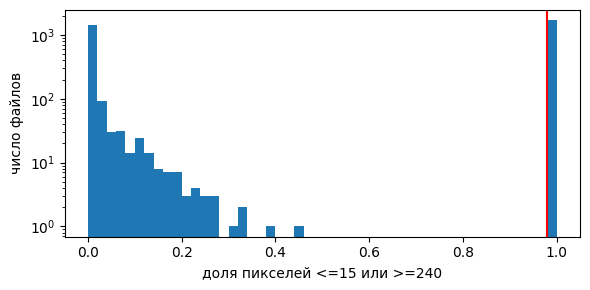

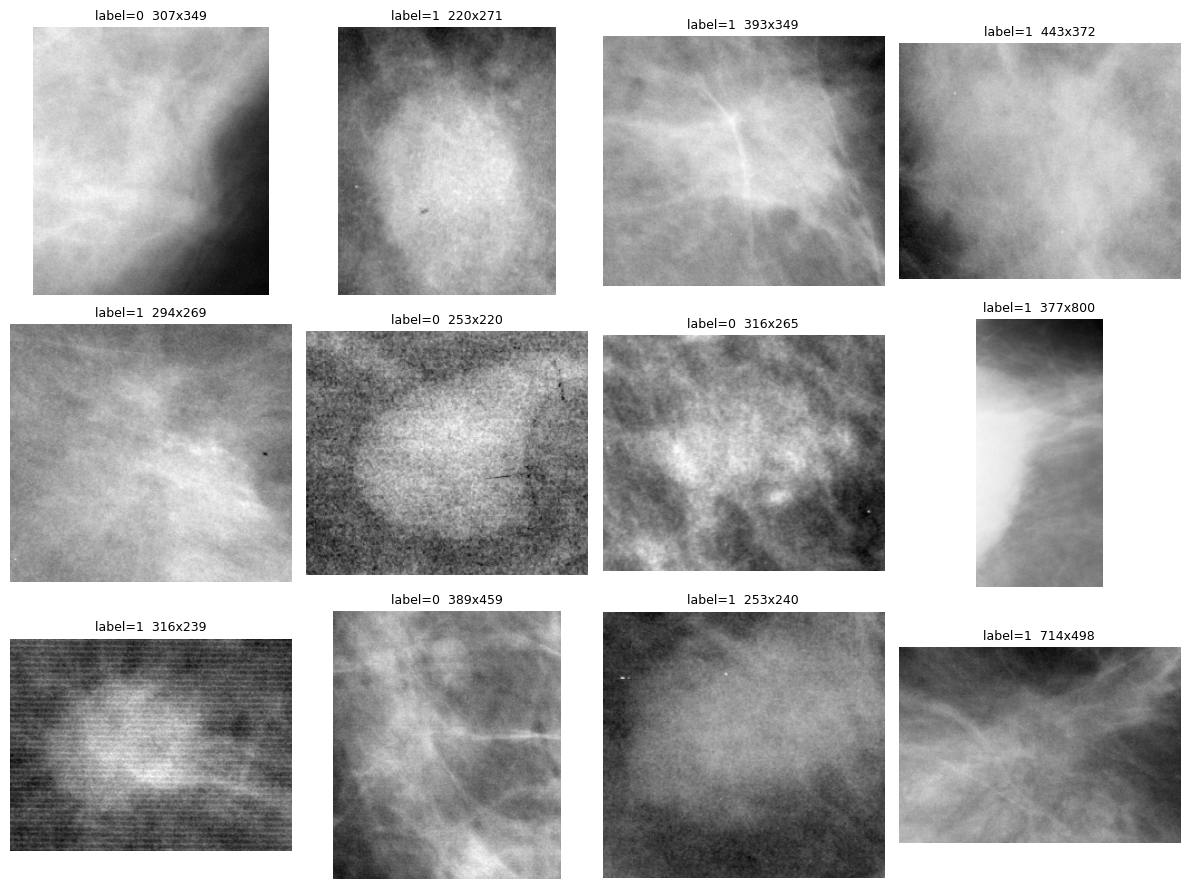

In [6]:
# Шаг 2. Диагностика: насколько исходный способ выбора файла был ошибочным
print(df_all["status"].value_counts().to_dict())
print("файлов-кандидатов на запись:", df_all["n_cand"].value_counts().to_dict())
print(f"Исходный способ вернул БИНАРНУЮ МАСКУ в {df_all['old_is_mask'].mean():.1%} записей")
same = (df_all["old_path"] == df_all["image_path"]).mean()
print(f"Исходный способ совпал с исправленным в {same:.1%} записей")

# гистограмма: должна быть двугорбой (кропы слева, маски справа у порога)
fr = [v[0] for v in _cache.values()]
plt.figure(figsize=(6, 3))
plt.hist(fr, bins=50); plt.yscale("log"); plt.axvline(C["MASK_THR"], color="r")
plt.xlabel("доля пикселей <=15 или >=240"); plt.ylabel("число файлов")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/qc_mask_threshold.png", dpi=200); plt.show()

# контрольная сетка: 12 случайных выбранных изображений -- это должны быть кропы
ok = df_all[df_all["status"] != "no_crop"]
smp = ok.sample(min(12, len(ok)), random_state=0)
fig, axs = plt.subplots(3, 4, figsize=(12, 9))
for ax, (_, r) in zip(axs.ravel(), smp.iterrows()):
    ax.imshow(Image.open(r["image_path"]).convert("L"), cmap="gray")
    ax.set_title(f"label={r['label']}  {int(r['orig_w'])}x{int(r['orig_h'])}", fontsize=9)
    ax.axis("off")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/qc_crops.png", dpi=150); plt.show()

**Что проверить:** Скопируйте мне вывод этой ячейки (4–5 строк). Если доля «исходный способ вернул БИНАРНУЮ МАСКУ» заметно больше 0%, это может объяснять результаты, близкие к случайным, и прежние числа в таблицах 1–4 использовать нельзя. Если 0%, проблема не в выборе файла. Оговорка: порядок файлов в glob на Drive может отличаться от того, что было у вас при первом запуске, поэтому это оценка. Откройте и пришлите картинки qc_crops.png и qc_mask_threshold.png из revision_v2/figures: на первой должны быть полутоновые снимки тканей, а не чёрно-белые силуэты; на гистограмме — два скопления (кропы слева, маски у порога справа).

In [7]:
# Шаг 2. Исключаем записи без кропа, фиксируем чистую таблицу
n0 = len(df_all)
df_all = df_all[df_all["status"] != "no_crop"].reset_index(drop=True)
df_all["record_id"] = np.arange(len(df_all))
print(f"исключено записей без кропа: {n0 - len(df_all)}; осталось {len(df_all)}")
print("размеры исходных кропов (px): min/median/max  W:",
      df_all["orig_w"].min(), df_all["orig_w"].median(), df_all["orig_w"].max(),
      "| H:", df_all["orig_h"].min(), df_all["orig_h"].median(), df_all["orig_h"].max())
df_all.to_csv(f"{OUT_DIR}/records_clean.csv", index=False)

исключено записей без кропа: 0; осталось 1696
размеры исходных кропов (px): min/median/max  W: 95 345.0 1086 | H: 126 343.0 1099


**Что проверить:** Если у всех записей нашёлся кроп, останется 1696 записей. Файл records_clean.csv — единая таблица для всех следующих шагов. Размеры исходных кропов (min, медиана, max) нужно привести в разделе методов.

## Шаг 3. Предобработка и кэш
Кроп дополняется до квадрата чёрными полями и приводится к 224×224. Результат кэшируется на Drive, поэтому дальше картинки не читаются заново.

In [8]:
# Шаг 3. Предобработка и кэш: кроп -> квадрат (чёрные поля, пропорции сохраняются) -> 224x224
def load_square(path, size):
    im = Image.open(path).convert("L")
    w, h = im.size
    s = max(w, h)
    canvas = Image.new("L", (s, s), 0)
    canvas.paste(im, ((s - w) // 2, (s - h) // 2))
    return np.asarray(canvas.resize((size, size), Image.BILINEAR), dtype=np.uint8)

h8 = hashlib.md5("".join(df_all["image_path"]).encode()).hexdigest()[:8]
CACHE = f"{OUT_DIR}/crops_{C['IMG_SIZE']}_{h8}.npy"
if os.path.exists(CACHE):
    X = np.load(CACHE)
else:
    X = np.stack([load_square(p, C["IMG_SIZE"]) for p in tqdm(df_all["image_path"])])
    np.save(CACHE, X)
y_all = df_all["label"].values.astype(np.int64)
print("X:", X.shape, X.dtype, "| средняя яркость:", round(float(X.mean()), 1))
assert len(X) == len(df_all) == len(y_all)

X: (1696, 224, 224) uint8 | средняя яркость: 116.3


**Что проверить:** Если средняя яркость близка к 0 или к 255, что-то не так: вернитесь к QC-рисунку из шага 2.

## Шаг 4. Разбиения по пациентам и таблицы набора данных
5-fold по пациентам со стратификацией; внутри обучающей части — валидация, тоже по пациентам.

In [9]:
# Шаг 4. Разбиения по ПАЦИЕНТАМ (5-fold, стратификация по меткам) + внутренняя валидация
# test = 1/5 данных, val = 1/5 от оставшихся, train = остальное (как 64/16/20 в статье)
def make_folds(df, mode, n_folds, seed):
    y = df["label"].values
    g = df["patient_id"].values
    idx = np.arange(len(df))
    if mode == "patient":
        outer = list(StratifiedGroupKFold(n_folds, shuffle=True, random_state=seed).split(idx, y, g))
    else:  # "record": случайное разбиение записей (нужно только для оценки утечки, Эксперимент E3)
        outer = list(StratifiedKFold(n_folds, shuffle=True, random_state=seed).split(idx, y))
    folds = []
    for k, (trv, te) in enumerate(outer):
        if mode == "patient":
            a, b = next(StratifiedGroupKFold(5, shuffle=True, random_state=seed).split(trv, y[trv], g[trv]))
        else:
            a, b = next(StratifiedKFold(5, shuffle=True, random_state=seed).split(trv, y[trv]))
        folds.append(dict(fold=k, train=trv[a], val=trv[b], test=te))
    return folds

FOLDS_PAT = make_folds(df_all, "patient", C["N_FOLDS"], C["SPLIT_SEED"])
FOLDS_REC = make_folds(df_all, "record", C["N_FOLDS"], C["SPLIT_SEED"])

# проверка отсутствия утечки: общих пациентов между частями быть не должно
pid = df_all["patient_id"].values
for name, folds in (("patient", FOLDS_PAT), ("record", FOLDS_REC)):
    ov = [len(set(pid[f["train"]]) & set(pid[f["test"]])) for f in folds]
    print(f"разбиение '{name}': пациентов, общих у train и test, по фолдам: {ov}")
    if name == "patient":
        assert sum(ov) == 0
        for f in folds:
            assert not (set(pid[f["train"]]) & set(pid[f["val"]]))
            assert not (set(pid[f["val"]]) & set(pid[f["test"]]))

разбиение 'patient': пациентов, общих у train и test, по фолдам: [0, 0, 0, 0, 0]
разбиение 'record': пациентов, общих у train и test, по фолдам: [201, 185, 177, 197, 192]


**Что проверить:** Для 'patient' должно быть [0, 0, 0, 0, 0] (ячейка остановится с ошибкой, если пациенты пересекаются). Для 'record' ненулевые числа — это и есть утечка, её влияние покажет эксперимент E3.

In [10]:
# Шаг 4. Таблицы структуры набора данных (R3.3) -- вставить в статью
t_orig = df_all.groupby(["orig_split", "pathology"]).size().unstack(fill_value=0)
t_orig["total"] = t_orig.sum(axis=1)
print(t_orig, "\n")
t_orig.to_csv(f"{TAB_DIR}/table_dataset_original_split.csv")

def fold_table(folds):
    rows = []
    for f in folds:
        for part in ("train", "val", "test"):
            d = df_all.iloc[f[part]]
            rows.append(dict(fold=f["fold"], part=part, records=len(d),
                             patients=d["patient_id"].nunique(), malignant=int(d["label"].sum()),
                             pct_malignant=round(100 * d["label"].mean(), 1)))
    return pd.DataFrame(rows)

ft = fold_table(FOLDS_PAT)
ft.to_csv(f"{TAB_DIR}/table_folds_patient.csv", index=False)
print(ft.pivot(index="fold", columns="part", values=["records", "patients", "pct_malignant"]))
print("\nдоля мажоритарного класса (accuracy тривиального классификатора):",
      round(max(y_all.mean(), 1 - y_all.mean()), 4))

pathology   BENIGN  BENIGN_WITHOUT_CALLBACK  MALIGNANT  total
orig_split                                                   
test           194                       37        147    378
train          577                      104        637   1318 

     records                patients               pct_malignant            
part    test   train    val     test  train    val          test train   val
fold                                                                        
0      355.0  1070.0  271.0    175.0  573.0  144.0          47.0  46.1  45.8
1      345.0  1070.0  281.0    181.0  568.0  143.0          48.1  47.0  40.9
2      367.0  1061.0  268.0    182.0  570.0  140.0          44.1  46.0  50.0
3      316.0  1111.0  269.0    173.0  575.0  144.0          43.7  45.5  52.4
4      313.0  1111.0  272.0    181.0  573.0  138.0          48.2  46.0  44.9

доля мажоритарного класса (accuracy тривиального классификатора): 0.5377


**Что проверить:** Три таблицы идут в статью (замечание R3.3). Строка «доля мажоритарного класса» — минимальный уровень, который должна превзойти модель. Раньше за случайный уровень принимали 50%, но при 53–54% не злокачественных тривиальный классификатор даёт около 53–54%.

## Шаг 5. Датасет, модели, обучение
Датасет с нормализацией ImageNet и аугментацией (включаются флагами), пять моделей, функция обучения одного запуска с early stopping. Эти ячейки только определяют функции, обучение не запускают.

In [11]:
# Шаг 5. Датасет и преобразования (нормализация ImageNet и аугментация -- включаются флагами)
IM_MEAN, IM_STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]

def make_transforms(use_norm, use_aug):
    aug = []
    if use_aug:
        aug = [transforms.RandomHorizontalFlip(),
               transforms.RandomVerticalFlip(),
               transforms.RandomAffine(degrees=15, translate=(0.05, 0.05),
                                       scale=(0.9, 1.1), fill=0),
               transforms.ColorJitter(brightness=0.2, contrast=0.2)]
    tail = [transforms.ToTensor()]
    if use_norm:
        tail.append(transforms.Normalize(IM_MEAN, IM_STD))
    return transforms.Compose(aug + tail), transforms.Compose(tail)   # (train, eval)

class CropDataset(Dataset):
    def __init__(self, X, y, idx, transform):
        self.X, self.y, self.idx, self.t = X, y, np.asarray(idx), transform
    def __len__(self):
        return len(self.idx)
    def __getitem__(self, i):
        j = self.idx[i]
        img = Image.fromarray(self.X[j]).convert("RGB")   # 1 канал -> 3 канала
        return self.t(img), int(self.y[j])

def seed_worker(_):
    s = torch.initial_seed() % 2**32
    np.random.seed(s); random.seed(s)

In [12]:
# Шаг 5. Модели
class SimpleCNN(nn.Module):          # исходная базовая CNN (для сопоставимости с первой версией)
    def __init__(self, size=224):
        super().__init__()
        self.conv1 = nn.Conv2d(3, 16, 3, padding=1)
        self.conv2 = nn.Conv2d(16, 32, 3, padding=1)
        self.pool = nn.MaxPool2d(2, 2)
        self.fc1 = nn.Linear(32 * (size // 4) * (size // 4), 128)
        self.fc2 = nn.Linear(128, 1)
    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))
        return self.fc2(F.relu(self.fc1(x.flatten(1))))

class CNNBN(nn.Module):              # более сильный baseline с нуля: 4 блока Conv-BN-ReLU-Pool + GAP
    def __init__(self):
        super().__init__()
        def block(i, o):
            return nn.Sequential(nn.Conv2d(i, o, 3, padding=1, bias=False),
                                 nn.BatchNorm2d(o), nn.ReLU(inplace=True), nn.MaxPool2d(2))
        self.features = nn.Sequential(block(3, 16), block(16, 32), block(32, 64), block(64, 128))
        self.pool, self.drop, self.fc = nn.AdaptiveAvgPool2d(1), nn.Dropout(0.3), nn.Linear(128, 1)
    def forward(self, x):
        return self.fc(self.drop(self.pool(self.features(x)).flatten(1)))

def build_model(name):
    if name == "cnn_simple":
        return SimpleCNN(C["IMG_SIZE"])
    if name == "cnn_bn":
        return CNNBN()
    w = models.ResNet50_Weights.IMAGENET1K_V1 if C["PRETRAINED"] else None
    m = models.resnet50(weights=w)
    for p in m.parameters():
        p.requires_grad = False                       # сначала замораживаем всё
    m.fc = nn.Sequential(nn.Linear(m.fc.in_features, 256), nn.ReLU(),
                         nn.Dropout(0.3), nn.Linear(256, 1))   # новая голова (обучается всегда)
    if name == "resnet_ft_l4":                        # + размораживаем layer4
        for p in m.layer4.parameters(): p.requires_grad = True
    elif name == "resnet_ft_l34":                     # + размораживаем layer3 и layer4
        for blk in (m.layer3, m.layer4):
            for p in blk.parameters(): p.requires_grad = True
    elif name != "resnet_frozen":
        raise ValueError(name)
    return m

def param_groups(model, name):
    if name.startswith("cnn"):
        return [dict(params=model.parameters(), lr=C["LR_SCRATCH"])]
    head = list(model.fc.parameters())
    ids = {id(p) for p in head}
    bb = [p for p in model.parameters() if p.requires_grad and id(p) not in ids]
    g = [dict(params=head, lr=C["LR_HEAD"])]
    if bb:
        g.append(dict(params=bb, lr=C["LR_BACKBONE"]))
    return g

def set_train_mode(model):
    # ВАЖНО: BatchNorm в замороженных блоках остаётся в eval-режиме, иначе model.train()
    # меняет их статистики и "замороженный" backbone на деле не заморожен
    model.train()
    for m in model.modules():
        if isinstance(m, nn.modules.batchnorm._BatchNorm):
            ps = list(m.parameters(recurse=False))
            if ps and not any(p.requires_grad for p in ps):
                m.eval()

In [13]:
# Шаг 5. Обучение одного запуска и предсказание
@torch.no_grad()
def predict(model, loader, use_amp=False):
    model.eval()
    ps, ys, tot = [], [], 0.0
    for xb, yb in loader:
        with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=use_amp):
            lg = model(xb.to(device, non_blocking=True))
        lg = lg.float().squeeze(1).cpu()
        tot += F.binary_cross_entropy_with_logits(lg, yb.float(), reduction="sum").item()
        ps.append(torch.sigmoid(lg).numpy()); ys.append(yb.numpy())
    p, yy = np.concatenate(ps), np.concatenate(ys)
    return p, yy, tot / len(yy)

def make_scaler(enabled):
    try:
        return torch.amp.GradScaler("cuda", enabled=enabled)
    except Exception:
        return torch.cuda.amp.GradScaler(enabled=enabled)

def train_one_run(exp, model_name, fold, seed, use_norm, use_aug, split_mode, save_weights=False):
    tag = f"{exp}__{model_name}__f{fold['fold']}__s{seed}"
    path = f"{RUN_DIR}/{tag}.json"
    if os.path.exists(path):                       # запуск уже выполнен -> читаем результат
        return json.load(open(path))
    t0 = time.time()
    run_seed = seed * 1000 + fold["fold"]
    set_seed(run_seed)
    tr_t, ev_t = make_transforms(use_norm, use_aug)
    g = torch.Generator(); g.manual_seed(run_seed)
    nw = C["NUM_WORKERS"]
    kw = dict(num_workers=nw, pin_memory=device.type == "cuda", persistent_workers=nw > 0)
    tr_dl = DataLoader(CropDataset(X, y_all, fold["train"], tr_t), batch_size=C["BATCH_SIZE"],
                       shuffle=True, drop_last=True, generator=g, worker_init_fn=seed_worker, **kw)
    va_dl = DataLoader(CropDataset(X, y_all, fold["val"], ev_t), batch_size=64, shuffle=False, **kw)
    te_dl = DataLoader(CropDataset(X, y_all, fold["test"], ev_t), batch_size=64, shuffle=False, **kw)

    model = build_model(model_name).to(device)
    opt = torch.optim.AdamW(param_groups(model, model_name), weight_decay=C["WEIGHT_DECAY"])
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=C["MAX_EPOCHS"])
    crit = nn.BCEWithLogitsLoss()
    use_amp = C["USE_AMP"] and device.type == "cuda"
    scaler = make_scaler(use_amp)

    best_auc, best_ep, best_state, bad, hist = -1.0, 0, None, 0, []
    for ep in range(1, C["MAX_EPOCHS"] + 1):
        set_train_mode(model)
        tl, n = 0.0, 0
        for xb, yb in tr_dl:
            xb = xb.to(device, non_blocking=True)
            yb = yb.float().unsqueeze(1).to(device)
            opt.zero_grad(set_to_none=True)
            with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=use_amp):
                loss = crit(model(xb), yb)
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
            tl += loss.item() * xb.size(0); n += xb.size(0)
        sched.step()
        vp, vy, vl = predict(model, va_dl, use_amp)
        v_auc = float(roc_auc_score(vy, vp))
        hist.append(dict(epoch=ep, train_loss=tl / n, val_loss=vl,
                         val_acc=float(((vp >= 0.5) == vy).mean()), val_auc=v_auc))
        if v_auc > best_auc + 1e-4:
            best_auc, best_ep, bad = v_auc, ep, 0
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        else:
            bad += 1
        if ep >= C["MIN_EPOCHS"] and bad >= C["PATIENCE"]:
            break

    model.load_state_dict(best_state)               # возвращаем лучшую по val AUC эпоху
    vp, vy, _ = predict(model, va_dl, use_amp)
    tp, ty, _ = predict(model, te_dl, use_amp)      # тестовый фолд используется один раз
    if save_weights:
        torch.save(best_state, f"{W_DIR}/{tag}.pt")
    res = dict(config=dict(exp=exp, model=model_name, fold=fold["fold"], seed=seed,
                           use_norm=use_norm, use_aug=use_aug, split_mode=split_mode),
               best_epoch=best_ep, best_val_auc=best_auc, history=hist,
               val_idx=fold["val"].tolist(), val_y=vy.tolist(), val_prob=np.round(vp, 6).tolist(),
               test_idx=fold["test"].tolist(), test_y=ty.tolist(), test_prob=np.round(tp, 6).tolist(),
               minutes=(time.time() - t0) / 60)
    json.dump(res, open(path, "w"))
    return res

def run_grid(exp, models_, use_norm, use_aug, split_mode):
    folds = FOLDS_PAT if split_mode == "patient" else FOLDS_REC
    for mn in models_:
        for f in folds:
            for s in C["TRAIN_SEEDS"]:
                sw = (exp == "E1" and f["fold"] == 0 and s == C["TRAIN_SEEDS"][0]
                      and mn in ("cnn_simple", "resnet_frozen", "resnet_ft_l4"))
                r = train_one_run(exp, mn, f, s, use_norm, use_aug, split_mode, save_weights=sw)
                tp, ty = np.array(r["test_prob"]), np.array(r["test_y"])
                print(f"{exp} | {mn:13s} | fold {f['fold']} | seed {s} | эпох {len(r['history']):2d} "
                      f"(лучшая {r['best_epoch']:2d}) | val AUC {r['best_val_auc']:.3f} | "
                      f"test acc@0.5 {((tp >= 0.5) == ty).mean():.3f} | "
                      f"test AUC {roc_auc_score(ty, tp):.3f} | {r['minutes']:.1f} мин")

In [14]:
# Шаг 5. Проверка здравого смысла (1-2 минуты): сеть ОБЯЗАНА переобучиться на 64 снимках.
# Если train accuracy не приближается к 1.0 -- в данных или коде есть ошибка, дальше не идти.
def sanity_overfit(n=64, epochs=40, model_name="resnet_ft_l4"):
    set_seed(0)
    idx = FOLDS_PAT[0]["train"][:n]
    _, ev_t = make_transforms(True, False)
    dl = DataLoader(CropDataset(X, y_all, idx, ev_t), batch_size=16, shuffle=True)
    m = build_model(model_name).to(device)
    opt = torch.optim.AdamW(param_groups(m, model_name), weight_decay=0)
    for ep in range(1, epochs + 1):
        set_train_mode(m); ok = 0
        for xb, yb in dl:
            xb, yb = xb.to(device), yb.float().unsqueeze(1).to(device)
            opt.zero_grad(); lg = m(xb)
            F.binary_cross_entropy_with_logits(lg, yb).backward(); opt.step()
            ok += ((lg > 0).float() == yb).sum().item()
        if ep % 10 == 0:
            print(f"эпоха {ep}: train accuracy на {n} снимках = {ok / n:.3f}")

sanity_overfit()

Downloading: "https://download.pytorch.org/models/resnet50-0676ba61.pth" to /root/.cache/torch/hub/checkpoints/resnet50-0676ba61.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 189MB/s]


эпоха 10: train accuracy на 64 снимках = 1.000
эпоха 20: train accuracy на 64 снимках = 1.000
эпоха 30: train accuracy на 64 снимках = 1.000
эпоха 40: train accuracy на 64 снимках = 1.000


**Что проверить:** Должно быть: train accuracy приближается к 1,0 (к 30–40-й эпохе). Если нет, в данных или в коде есть ошибка: дальше не запускайте и пришлите мне вывод и QC-рисунки шага 2.

## Шаг 6. Эксперимент E1 (основной)
5 моделей × 5 фолдов = 25 запусков. Ориентировочно на GPU T4 это от 40 минут до 1,5 часов (я не могла измерить на GPU; точнее покажет первый запуск — время каждого печатается). Перед запуском не меняйте CONFIG.

In [15]:
# Шаг 6. ЭКСПЕРИМЕНТ E1 (основной): 5 моделей x 5 фолдов по пациентам.  ДОЛГО.
# Нормализация ImageNet + аугментация, early stopping по val AUC, тест -- один раз на фолд.
# Результаты каждого запуска пишутся в revision_v2/runs/*.json; при обрыве сессии
# просто запустите ячейку снова -- завершённые запуски пропускаются.
MAIN_MODELS = ["cnn_simple", "cnn_bn", "resnet_frozen", "resnet_ft_l4", "resnet_ft_l34"]
run_grid("E1", MAIN_MODELS, use_norm=True, use_aug=True, split_mode="patient")

E1 | cnn_simple    | fold 0 | seed 0 | эпох 19 (лучшая 12) | val AUC 0.679 | test acc@0.5 0.558 | test AUC 0.596 | 1.1 мин
E1 | cnn_simple    | fold 1 | seed 0 | эпох 12 (лучшая  5) | val AUC 0.629 | test acc@0.5 0.528 | test AUC 0.532 | 0.7 мин
E1 | cnn_simple    | fold 2 | seed 0 | эпох 20 (лучшая 13) | val AUC 0.567 | test acc@0.5 0.635 | test AUC 0.685 | 1.2 мин
E1 | cnn_simple    | fold 3 | seed 0 | эпох 10 (лучшая  3) | val AUC 0.598 | test acc@0.5 0.573 | test AUC 0.562 | 0.6 мин
E1 | cnn_simple    | fold 4 | seed 0 | эпох  8 (лучшая  1) | val AUC 0.528 | test acc@0.5 0.415 | test AUC 0.447 | 0.5 мин
E1 | cnn_bn        | fold 0 | seed 0 | эпох 23 (лучшая 16) | val AUC 0.689 | test acc@0.5 0.569 | test AUC 0.593 | 1.4 мин
E1 | cnn_bn        | fold 1 | seed 0 | эпох 29 (лучшая 22) | val AUC 0.641 | test acc@0.5 0.594 | test AUC 0.631 | 1.8 мин
E1 | cnn_bn        | fold 2 | seed 0 | эпох 11 (лучшая  4) | val AUC 0.560 | test acc@0.5 0.594 | test AUC 0.634 | 0.7 мин
E1 | cnn_bn     

**Что проверить:** После каждого запуска печатается строка: число эпох, лучшая эпоха, AUC на валидации, accuracy и AUC на тесте. Эти числа промежуточные (порог 0,5); итоговые таблицы строит шаг 7. Веса фолда 0 сохраняются для шага 10.

## Шаг 7. Анализ E1: метрики, доверительные интервалы, рисунки
Здесь получаются все таблицы и рисунки для раздела «Результаты».

In [16]:
# Шаг 7. Функции анализа: метрики, порог по валидации, объединение фолдов, бутстреп по пациентам
METRICS = ["acc", "sens", "spec", "prec", "f1", "auc"]
LABEL = {"cnn_simple": "Simple CNN (scratch)", "cnn_bn": "CNN+BN (scratch)",
         "resnet_frozen": "ResNet50 (frozen)", "resnet_ft_l4": "ResNet50 (FT layer4)",
         "resnet_ft_l34": "ResNet50 (FT layer3+4)"}
SEED0 = C["TRAIN_SEEDS"][0]
PID = df_all["patient_id"].values
POS = [np.where(PID == u)[0] for u in np.unique(PID)]      # индексы записей каждого пациента

def metrics_from(y, p, pred):
    tp = int(((pred == 1) & (y == 1)).sum()); tn = int(((pred == 0) & (y == 0)).sum())
    fp = int(((pred == 1) & (y == 0)).sum()); fn = int(((pred == 0) & (y == 1)).sum())
    sens = tp / (tp + fn) if tp + fn else np.nan          # sensitivity = recall (класс "злокачественная")
    spec = tn / (tn + fp) if tn + fp else np.nan
    prec = tp / (tp + fp) if tp + fp else np.nan
    ok = np.isfinite(prec) and np.isfinite(sens) and prec + sens > 0
    f1 = 2 * prec * sens / (prec + sens) if ok else np.nan
    return dict(acc=(tp + tn) / len(y), sens=sens, spec=spec, prec=prec, f1=f1, auc=roc_auc_score(y, p))

def youden_thr(y, p):                                     # порог выбирается ТОЛЬКО по валидации
    fpr, tpr, thr = roc_curve(y, p)
    t = thr[int(np.argmax(tpr - fpr))]
    return float(min(max(t, 0.0), 1.0)) if np.isfinite(t) else 0.5

def load_runs(exp, model, seed):
    paths = sorted(glob.glob(f"{RUN_DIR}/{exp}__{model}__f*__s{seed}.json"))
    return [json.load(open(p)) for p in paths]

def pooled(exp, model, seed):
    runs = load_runs(exp, model, seed)
    if len(runs) != C["N_FOLDS"]:
        raise RuntimeError(f"{exp}/{model}/seed{seed}: готово {len(runs)} из {C['N_FOLDS']} фолдов")
    N = len(df_all)
    prob, pred_y, pred05 = np.full(N, np.nan), np.full(N, -1), np.full(N, -1)
    thrs = []
    for r in runs:
        thr = youden_thr(np.array(r["val_y"]), np.array(r["val_prob"])); thrs.append(thr)
        idx, pr = np.array(r["test_idx"]), np.array(r["test_prob"])
        prob[idx] = pr; pred_y[idx] = (pr >= thr).astype(int); pred05[idx] = (pr >= 0.5).astype(int)
    assert not np.isnan(prob).any(), "не все записи попали в тестовые фолды"
    return dict(prob=prob, pred_y=pred_y, pred05=pred05, thr=thrs)

def cluster_boot(P, key, n_boot, seed=123):
    # бутстреп ПО ПАЦИЕНТАМ (записи одного пациента зависимы); одни и те же выборки для всех моделей
    rng = np.random.default_rng(seed)
    out = {m: {k: np.empty(n_boot) for k in METRICS} for m in P}
    for b in range(n_boot):
        ii = np.concatenate([POS[d] for d in rng.integers(0, len(POS), len(POS))])
        for m in P:
            mm = metrics_from(y_all[ii], P[m]["prob"][ii], P[m][key][ii])
            for k in METRICS:
                out[m][k][b] = mm[k]
    return out

def fmt(point, arr):
    lo, hi = np.nanpercentile(arr, [2.5, 97.5])
    return f"{point:.3f} [{lo:.3f}-{hi:.3f}]"

Здесь только определения функций; вывода нет. Порог выбирается по валидации, интервалы строятся бутстрепом по пациентам (записи одного пациента зависимы).

In [17]:
# Шаг 7. ГЛАВНАЯ ТАБЛИЦА СТАТЬИ: объединённые прогнозы тестовых фолдов (каждая запись -- ровно один раз)
P = {m: pooled("E1", m, SEED0) for m in MAIN_MODELS}
BT = cluster_boot(P, "pred_y", C["N_BOOT"])

rows = []
for m in MAIN_MODELS:
    pt = metrics_from(y_all, P[m]["prob"], P[m]["pred_y"])
    rows.append(dict(model=LABEL[m], **{k: fmt(pt[k], BT[m][k]) for k in METRICS}))
maj = max(y_all.mean(), 1 - y_all.mean())
rows.append(dict(model="Majority class (trivial)", acc=f"{maj:.3f}", sens="-", spec="-",
                 prec="-", f1="-", auc="0.500"))
tab_main = pd.DataFrame(rows)
tab_main.to_csv(f"{TAB_DIR}/table_main_pooled_ci.csv", index=False)
print("Порог классификации выбран на валидации (критерий Юдена); 95% ДИ -- бутстреп по пациентам")
print(tab_main.to_string(index=False))

# дополнение: те же модели при пороге 0.5 (без доверительных интервалов)
rows05 = []
for m in MAIN_MODELS:
    pt = metrics_from(y_all, P[m]["prob"], P[m]["pred05"])
    rows05.append(dict(model=LABEL[m], **{k: round(float(pt[k]), 3) for k in METRICS}))
pd.DataFrame(rows05).to_csv(f"{TAB_DIR}/table_main_threshold05.csv", index=False)
print("\nпри пороге 0.5:\n", pd.DataFrame(rows05).to_string(index=False))

Порог классификации выбран на валидации (критерий Юдена); 95% ДИ -- бутстреп по пациентам
                   model                 acc                sens                spec                prec                  f1                 auc
    Simple CNN (scratch) 0.548 [0.521-0.576] 0.566 [0.525-0.607] 0.532 [0.495-0.569] 0.510 [0.465-0.553] 0.537 [0.500-0.572] 0.582 [0.549-0.614]
        CNN+BN (scratch) 0.584 [0.557-0.611] 0.552 [0.514-0.593] 0.611 [0.574-0.649] 0.549 [0.506-0.591] 0.551 [0.515-0.583] 0.600 [0.568-0.632]
       ResNet50 (frozen) 0.699 [0.673-0.725] 0.648 [0.608-0.686] 0.743 [0.711-0.776] 0.685 [0.642-0.725] 0.666 [0.633-0.697] 0.760 [0.733-0.787]
    ResNet50 (FT layer4) 0.731 [0.708-0.753] 0.712 [0.677-0.746] 0.748 [0.715-0.778] 0.708 [0.666-0.746] 0.710 [0.680-0.739] 0.785 [0.759-0.809]
  ResNet50 (FT layer3+4) 0.729 [0.707-0.753] 0.672 [0.634-0.709] 0.777 [0.748-0.806] 0.722 [0.680-0.761] 0.696 [0.663-0.726] 0.792 [0.767-0.816]
Majority class (trivial)               0

**Что проверить:** Главная таблица статьи: объединённые прогнозы всех тестовых фолдов с 95% доверительными интервалами и строкой тривиального классификатора. Sensitivity — то же, что recall для класса «злокачественная». Файлы: table_main_pooled_ci.csv и table_main_threshold05.csv.

In [18]:
# Шаг 7. Парные сравнения моделей (разность метрик, 95% ДИ, приблизительное бутстреп p-значение)
PAIRS = [("resnet_frozen", "cnn_simple"), ("resnet_frozen", "cnn_bn"),
         ("resnet_ft_l4", "resnet_frozen"), ("resnet_ft_l34", "resnet_ft_l4")]
rows = []
for a, b in PAIRS:
    pa = metrics_from(y_all, P[a]["prob"], P[a]["pred_y"])
    pb = metrics_from(y_all, P[b]["prob"], P[b]["pred_y"])
    for k in ("acc", "auc"):
        d = BT[a][k] - BT[b][k]
        lo, hi = np.percentile(d, [2.5, 97.5])
        p = min(1.0, 2 * min((d <= 0).mean(), (d >= 0).mean()))
        rows.append(dict(comparison=f"{LABEL[a]} - {LABEL[b]}", metric=k,
                         diff=f"{pa[k] - pb[k]:+.3f}", ci95=f"[{lo:+.3f}, {hi:+.3f}]", p_boot=round(p, 4)))
tab_pairs = pd.DataFrame(rows)
tab_pairs.to_csv(f"{TAB_DIR}/table_pairwise_differences.csv", index=False)
print(tab_pairs.to_string(index=False))

# разброс по фолдам и по seed (R2.3: стабильность при повторных запусках)
rows = []
for m in MAIN_MODELS:
    for s in C["TRAIN_SEEDS"]:
        for r in load_runs("E1", m, s):
            vy, vp = np.array(r["val_y"]), np.array(r["val_prob"])
            ty, tp = np.array(r["test_y"]), np.array(r["test_prob"])
            mm = metrics_from(ty, tp, (tp >= youden_thr(vy, vp)).astype(int))
            rows.append(dict(model=LABEL[m], seed=s, fold=r["config"]["fold"],
                             best_epoch=r["best_epoch"], **mm))
pf = pd.DataFrame(rows)
pf.to_csv(f"{TAB_DIR}/table_per_fold.csv", index=False)
summ_pf = pf.groupby("model", sort=False)[METRICS].agg(["mean", "std"]).round(3)
summ_pf.to_csv(f"{TAB_DIR}/table_fold_mean_sd.csv")
print("\nсреднее и SD по запускам (фолды x seed):\n", summ_pf.to_string())

                                   comparison metric   diff             ci95  p_boot
     ResNet50 (frozen) - Simple CNN (scratch)    acc +0.152 [+0.118, +0.186]   0.000
     ResNet50 (frozen) - Simple CNN (scratch)    auc +0.178 [+0.140, +0.214]   0.000
         ResNet50 (frozen) - CNN+BN (scratch)    acc +0.116 [+0.082, +0.147]   0.000
         ResNet50 (frozen) - CNN+BN (scratch)    auc +0.160 [+0.124, +0.196]   0.000
     ResNet50 (FT layer4) - ResNet50 (frozen)    acc +0.032 [+0.009, +0.054]   0.005
     ResNet50 (FT layer4) - ResNet50 (frozen)    auc +0.025 [+0.003, +0.048]   0.030
ResNet50 (FT layer3+4) - ResNet50 (FT layer4)    acc -0.002 [-0.022, +0.019]   0.832
ResNet50 (FT layer3+4) - ResNet50 (FT layer4)    auc +0.007 [-0.010, +0.025]   0.427

среднее и SD по запускам (фолды x seed):
                           acc          sens          spec          prec            f1           auc       
                         mean    std   mean    std   mean    std   mean    std   mean

**Что проверить:** Парные разности с интервалами показывают, какие различия между моделями не объясняются шумом. p_boot приблизительное (бутстреп). Если интервал разности содержит 0, различие в тексте как значимое подавать нельзя. Объединённый AUC может отличаться от среднего AUC по фолдам, потому что модели разных фолдов откалиброваны по-разному; в статье честно приводятся обе величины.

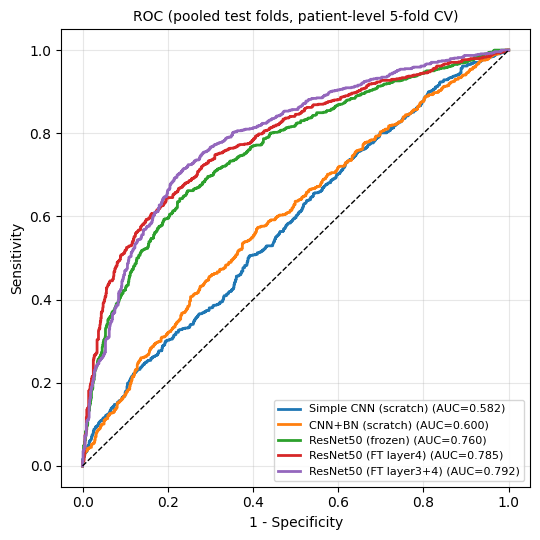

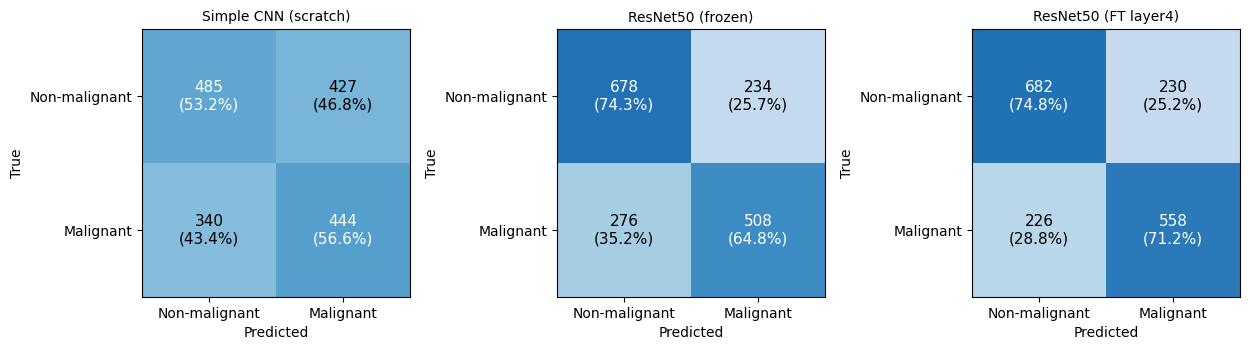

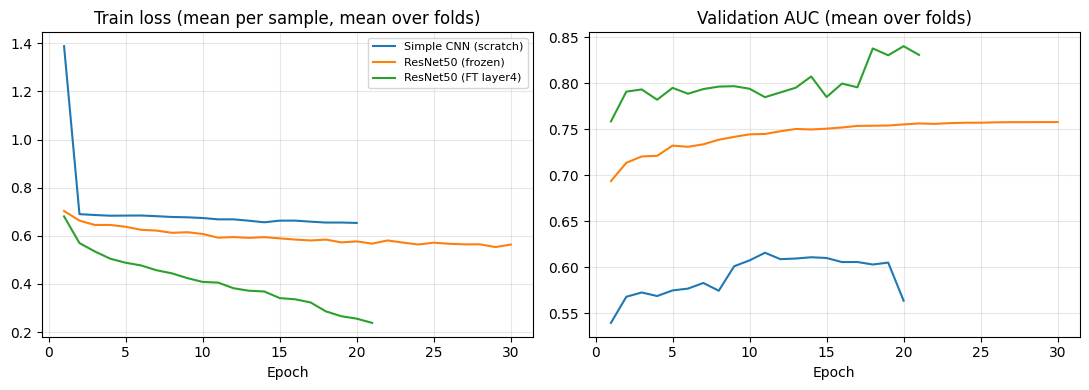

In [19]:
# Шаг 7. Рисунки: ROC-кривые, матрицы ошибок, кривые обучения (R2.7)
def plot_roc(P, names, fname):
    plt.figure(figsize=(5.5, 5.5))
    for m in names:
        fpr, tpr, _ = roc_curve(y_all, P[m]["prob"])
        plt.plot(fpr, tpr, lw=2, label=f"{LABEL[m]} (AUC={roc_auc_score(y_all, P[m]['prob']):.3f})")
    plt.plot([0, 1], [0, 1], "k--", lw=1)
    plt.xlabel("1 - Specificity"); plt.ylabel("Sensitivity")
    plt.title("ROC (pooled test folds, patient-level 5-fold CV)", fontsize=10)
    plt.legend(loc="lower right", fontsize=8); plt.grid(alpha=0.3); plt.tight_layout()
    plt.savefig(f"{FIG_DIR}/{fname}", dpi=600, bbox_inches="tight"); plt.show()

def plot_cm(P, names, fname):
    fig, axs = plt.subplots(1, len(names), figsize=(4.2 * len(names), 4))
    for ax, m in zip(np.atleast_1d(axs), names):
        cm = np.array([[((y_all == a) & (P[m]["pred_y"] == b)).sum() for b in (0, 1)] for a in (0, 1)])
        rn = cm / cm.sum(1, keepdims=True)                     # доли внутри истинного класса
        ax.imshow(rn, cmap="Blues", vmin=0, vmax=1)
        for i in range(2):
            for j in range(2):
                ax.text(j, i, f"{cm[i, j]}\n({100 * rn[i, j]:.1f}%)", ha="center", va="center",
                        fontsize=11, color="white" if rn[i, j] > 0.5 else "black")
        ax.set_xticks([0, 1]); ax.set_xticklabels(["Non-malignant", "Malignant"])
        ax.set_yticks([0, 1]); ax.set_yticklabels(["Non-malignant", "Malignant"])
        ax.set_xlabel("Predicted"); ax.set_ylabel("True"); ax.set_title(LABEL[m], fontsize=10)
    plt.tight_layout(); plt.savefig(f"{FIG_DIR}/{fname}", dpi=600, bbox_inches="tight"); plt.show()

def plot_curves(models_, fname):
    fig, axs = plt.subplots(1, 2, figsize=(11, 4))
    for m in models_:
        hs = [r["history"] for r in load_runs("E1", m, SEED0)]
        L = max(len(h) for h in hs)
        for ax, key in zip(axs, ("train_loss", "val_auc")):
            arr = np.full((len(hs), L), np.nan)
            for i, h in enumerate(hs):
                arr[i, :len(h)] = [e[key] for e in h]
            ax.plot(range(1, L + 1), np.nanmean(arr, 0), label=LABEL[m])
    axs[0].set_title("Train loss (mean per sample, mean over folds)")
    axs[1].set_title("Validation AUC (mean over folds)")
    for ax in axs:
        ax.set_xlabel("Epoch"); ax.grid(alpha=0.3)
    axs[0].legend(fontsize=8); plt.tight_layout()
    plt.savefig(f"{FIG_DIR}/{fname}", dpi=600, bbox_inches="tight"); plt.show()

THREE = ["cnn_simple", "resnet_frozen", "resnet_ft_l4"]       # три основные модели статьи
plot_roc(P, MAIN_MODELS, "fig_roc_all_models.png")
plot_cm(P, THREE, "fig_confusion_matrices.png")
plot_curves(THREE, "fig_learning_curves.png")

**Что проверить:** Сохраняются fig_roc_all_models.png, fig_confusion_matrices.png и fig_learning_curves.png (600 dpi), которых просили рецензенты. Кривые обучения показывают, переобучается ли модель на самом деле.

## Шаг 8. Эксперимент E2: нормализация и аугментация
Показывает, насколько результаты зависят от предобработки. Комбинация «нет / нет» воспроизводит протокол исходной версии. 2 модели × 3 конфигурации × 5 фолдов = 30 запусков, ориентировочно 1–2 часа. Запускайте после шага 7.

In [20]:
# Шаг 8. ЭКСПЕРИМЕНТ E2: влияние нормализации и аугментации (R1.3, R2.4).  ДОЛГО.
# Полный вариант (норм. да / аугм. да) -- это E1. Здесь три остальные комбинации;
# комбинация "нет / нет" воспроизводит протокол исходной версии статьи.
E2_MODELS = ["resnet_frozen", "resnet_ft_l4"]
E2_CFG = {"E2_n0a0": (False, False), "E2_n1a0": (True, False), "E2_n0a1": (False, True)}
for tag, (un, ua) in E2_CFG.items():
    run_grid(tag, E2_MODELS, use_norm=un, use_aug=ua, split_mode="patient")

E2_n0a0 | resnet_frozen | fold 0 | seed 0 | эпох 17 (лучшая 10) | val AUC 0.817 | test acc@0.5 0.687 | test AUC 0.736 | 0.7 мин
E2_n0a0 | resnet_frozen | fold 1 | seed 0 | эпох 17 (лучшая 10) | val AUC 0.745 | test acc@0.5 0.672 | test AUC 0.753 | 0.7 мин
E2_n0a0 | resnet_frozen | fold 2 | seed 0 | эпох 30 (лучшая 28) | val AUC 0.741 | test acc@0.5 0.744 | test AUC 0.818 | 1.2 мин
E2_n0a0 | resnet_frozen | fold 3 | seed 0 | эпох 30 (лучшая 24) | val AUC 0.789 | test acc@0.5 0.709 | test AUC 0.756 | 1.2 мин
E2_n0a0 | resnet_frozen | fold 4 | seed 0 | эпох 17 (лучшая 10) | val AUC 0.780 | test acc@0.5 0.703 | test AUC 0.783 | 0.7 мин
E2_n0a0 | resnet_ft_l4  | fold 0 | seed 0 | эпох 30 (лучшая 24) | val AUC 0.846 | test acc@0.5 0.721 | test AUC 0.775 | 1.4 мин
E2_n0a0 | resnet_ft_l4  | fold 1 | seed 0 | эпох 15 (лучшая  8) | val AUC 0.753 | test acc@0.5 0.704 | test AUC 0.770 | 0.7 мин
E2_n0a0 | resnet_ft_l4  | fold 2 | seed 0 | эпох 14 (лучшая  7) | val AUC 0.790 | test acc@0.5 0.766 | t

In [21]:
# Шаг 8. Таблица влияния предобработки (R1.3, R2.4): AUC и accuracy с 95% ДИ
def summ(exp, m, n_boot=1000):
    Pm = {m: pooled(exp, m, SEED0)}
    Bm = cluster_boot(Pm, "pred_y", n_boot)
    pt = metrics_from(y_all, Pm[m]["prob"], Pm[m]["pred_y"])
    return {k: fmt(pt[k], Bm[m][k]) for k in ("acc", "auc")}

CFG_NAMES = [("E2_n0a0", "no", "no"), ("E2_n1a0", "yes", "no"),
             ("E2_n0a1", "no", "yes"), ("E1", "yes", "yes")]
rows = []
for m in E2_MODELS:
    for exp, nm, ag in CFG_NAMES:
        rows.append(dict(model=LABEL[m], ImageNet_norm=nm, augmentation=ag, **summ(exp, m)))
tab_e2 = pd.DataFrame(rows)
tab_e2.to_csv(f"{TAB_DIR}/table_ablation_preprocessing.csv", index=False)
print(tab_e2.to_string(index=False))

               model ImageNet_norm augmentation                 acc                 auc
   ResNet50 (frozen)            no           no 0.693 [0.666-0.718] 0.763 [0.735-0.791]
   ResNet50 (frozen)           yes           no 0.695 [0.671-0.719] 0.737 [0.705-0.765]
   ResNet50 (frozen)            no          yes 0.690 [0.665-0.715] 0.753 [0.726-0.779]
   ResNet50 (frozen)           yes          yes 0.699 [0.673-0.726] 0.760 [0.732-0.788]
ResNet50 (FT layer4)            no           no 0.719 [0.696-0.741] 0.782 [0.758-0.804]
ResNet50 (FT layer4)           yes           no 0.715 [0.689-0.737] 0.784 [0.757-0.808]
ResNet50 (FT layer4)            no          yes 0.721 [0.697-0.744] 0.791 [0.765-0.815]
ResNet50 (FT layer4)           yes          yes 0.731 [0.708-0.753] 0.785 [0.760-0.809]


**Что проверить:** Таблица: как меняются accuracy и AUC при включении нормализации и аугментации. Файл: table_ablation_preprocessing.csv.

## Шаг 9. Эксперимент E3: влияние утечки данных
Те же модели, но записи делятся случайно: один пациент может быть и в обучении, и в тесте. Сравнение с E1 показывает, насколько утечка завышает метрики. 10 запусков, ориентировочно 20–40 минут.

In [22]:
# Шаг 9. ЭКСПЕРИМЕНТ E3: насколько утечка данных завышает метрики.  ДОЛГО.
# То же обучение, но записи делятся случайно (один пациент может попасть и в train, и в test).
run_grid("E3", E2_MODELS, use_norm=True, use_aug=True, split_mode="record")

E3 | resnet_frozen | fold 0 | seed 0 | эпох 30 (лучшая 26) | val AUC 0.792 | test acc@0.5 0.709 | test AUC 0.771 | 2.0 мин
E3 | resnet_frozen | fold 1 | seed 0 | эпох 30 (лучшая 28) | val AUC 0.713 | test acc@0.5 0.699 | test AUC 0.757 | 2.0 мин
E3 | resnet_frozen | fold 2 | seed 0 | эпох 30 (лучшая 23) | val AUC 0.802 | test acc@0.5 0.676 | test AUC 0.712 | 2.0 мин
E3 | resnet_frozen | fold 3 | seed 0 | эпох 30 (лучшая 30) | val AUC 0.777 | test acc@0.5 0.740 | test AUC 0.815 | 2.0 мин
E3 | resnet_frozen | fold 4 | seed 0 | эпох 30 (лучшая 24) | val AUC 0.766 | test acc@0.5 0.693 | test AUC 0.752 | 2.0 мин
E3 | resnet_ft_l4  | fold 0 | seed 0 | эпох 10 (лучшая  3) | val AUC 0.836 | test acc@0.5 0.706 | test AUC 0.809 | 0.7 мин
E3 | resnet_ft_l4  | fold 1 | seed 0 | эпох 13 (лучшая  6) | val AUC 0.797 | test acc@0.5 0.758 | test AUC 0.822 | 0.9 мин
E3 | resnet_ft_l4  | fold 2 | seed 0 | эпох 10 (лучшая  3) | val AUC 0.860 | test acc@0.5 0.699 | test AUC 0.769 | 0.7 мин
E3 | resnet_ft_l

In [23]:
# Шаг 9. Таблица: разбиение по пациентам vs случайное разбиение записей (утечка данных)
rows = []
for m in E2_MODELS:
    for exp, desc in (("E1", "patient-level split (correct)"), ("E3", "record-level split (leakage)")):
        rows.append(dict(model=LABEL[m], split=desc, **summ(exp, m)))
tab_e3 = pd.DataFrame(rows)
tab_e3.to_csv(f"{TAB_DIR}/table_leakage_ablation.csv", index=False)
print(tab_e3.to_string(index=False))

frac = [float(np.mean(np.isin(PID[f["test"]], PID[f["train"]]))) for f in FOLDS_REC]
print("\nДоля тестовых записей, чей пациент есть и в train (разбиение по записям):",
      [round(x, 3) for x in frac])

               model                         split                 acc                 auc
   ResNet50 (frozen) patient-level split (correct) 0.699 [0.673-0.726] 0.760 [0.732-0.788]
   ResNet50 (frozen)  record-level split (leakage) 0.702 [0.676-0.729] 0.760 [0.732-0.787]
ResNet50 (FT layer4) patient-level split (correct) 0.731 [0.708-0.753] 0.785 [0.760-0.809]
ResNet50 (FT layer4)  record-level split (leakage) 0.738 [0.714-0.762] 0.802 [0.779-0.827]

Доля тестовых записей, чей пациент есть и в train (разбиение по записям): [0.644, 0.617, 0.552, 0.614, 0.622]


**Что проверить:** Если при разбиении по записям метрики заметно выше, чем при разбиении по пациентам, это количественное доказательство утечки. Файл: table_leakage_ablation.csv.

## Шаг 10 (по желанию). Карты признаков обученных моделей
Заменяет рисунки 3 и 4 из первой версии.

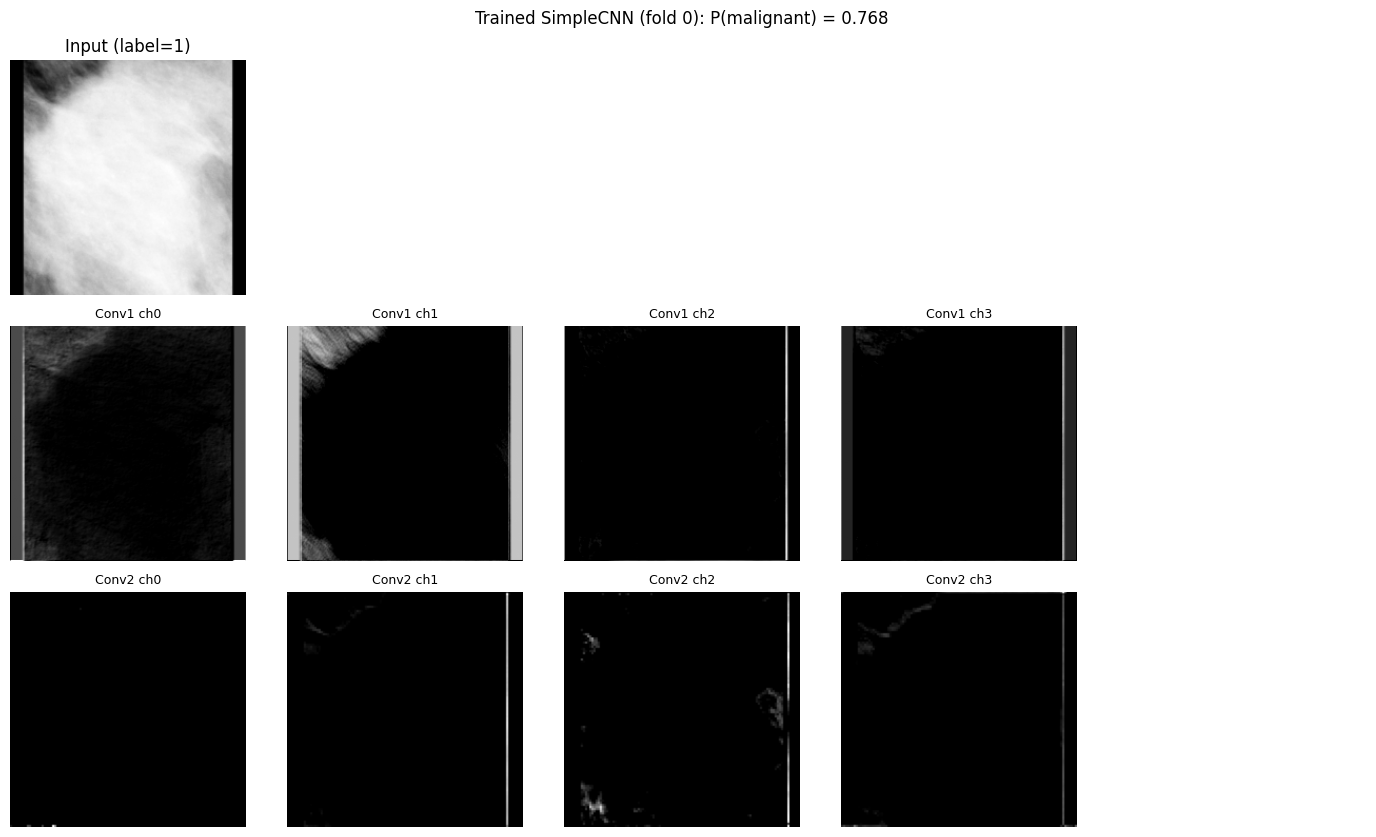

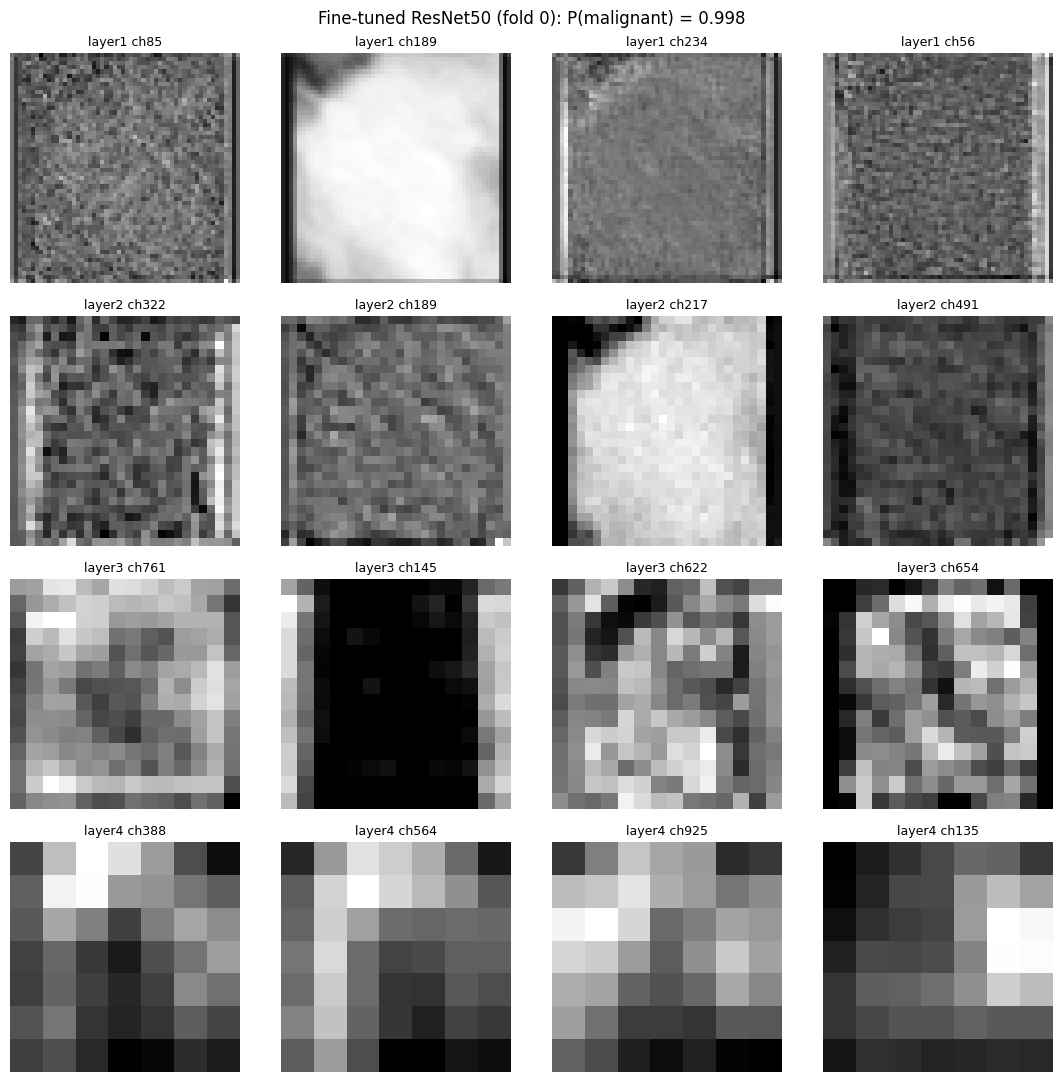

In [24]:
# Шаг 10 (по желанию). Карты признаков ОБУЧЕННЫХ моделей (веса фолда 0 сохранены в Шаге 6).
# В исходной версии рис. 3 строился на model = SimpleCNN() -- необученной сети со случайными весами.
# берём злокачественную запись теста фолда 0, которую ResNet классифицировал наиболее уверенно верно
r0 = json.load(open(f"{RUN_DIR}/E1__resnet_ft_l4__f0__s{SEED0}.json"))
tp0, ty0, ti0 = np.array(r0["test_prob"]), np.array(r0["test_y"]), np.array(r0["test_idx"])
j = int(ti0[np.argmax(np.where(ty0 == 1, tp0, -1))])
_, ev_t = make_transforms(True, False)
x = ev_t(Image.fromarray(X[j]).convert("RGB")).unsqueeze(0).to(device)

def load_trained(name):
    m = build_model(name)
    m.load_state_dict(torch.load(f"{W_DIR}/E1__{name}__f0__s{SEED0}.pt", map_location="cpu"))
    return m.to(device).eval()

# --- SimpleCNN ---
cnn = load_trained("cnn_simple")
with torch.no_grad():
    c1 = F.relu(cnn.conv1(x)); c2 = F.relu(cnn.conv2(cnn.pool(c1))); pr = torch.sigmoid(cnn(x)).item()
fig, axs = plt.subplots(3, 5, figsize=(14, 8.5))
for ax in axs.ravel(): ax.axis("off")
axs[0, 0].imshow(X[j], cmap="gray"); axs[0, 0].set_title(f"Input (label={y_all[j]})")
for i in range(4):
    axs[1, i].imshow(c1[0, i].cpu(), cmap="gray"); axs[1, i].set_title(f"Conv1 ch{i}", fontsize=9)
    axs[2, i].imshow(c2[0, i].cpu(), cmap="gray"); axs[2, i].set_title(f"Conv2 ch{i}", fontsize=9)
fig.suptitle(f"Trained SimpleCNN (fold 0): P(malignant) = {pr:.3f}")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/fig_feature_maps_cnn.png", dpi=300); plt.show()

# --- ResNet50 (fine-tuned layer4, fold 0) ---
net = load_trained("resnet_ft_l4")
fm, hs = {}, []
def hook(n):
    def h(mod, inp, out): fm[n] = out.detach().cpu()[0]
    return h
for n in ("layer1", "layer2", "layer3", "layer4"):
    hs.append(getattr(net, n).register_forward_hook(hook(n)))
with torch.no_grad():
    pr = torch.sigmoid(net(x)).item()
for h in hs: h.remove()
fig, axs = plt.subplots(4, 4, figsize=(11, 11))
for r_, n in enumerate(("layer1", "layer2", "layer3", "layer4")):
    top = np.argsort(fm[n].mean(dim=(1, 2)).numpy())[-4:][::-1]        # 4 самых активных канала
    for c_, ch in enumerate(top):
        axs[r_, c_].imshow(fm[n][ch], cmap="gray"); axs[r_, c_].axis("off")
        axs[r_, c_].set_title(f"{n} ch{ch}", fontsize=9)
fig.suptitle(f"Fine-tuned ResNet50 (fold 0): P(malignant) = {pr:.3f}")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/fig_feature_maps_resnet.png", dpi=300); plt.show()

**Что проверить:** Карты признаков — иллюстрация, а не доказательство того, что модель смотрит на лезию; утверждений о «диагностически значимых областях» без дополнительных методов (например Grad-CAM с оценкой) в тексте лучше не делать.

## Шаг 11. Обновлённая схема эксперимента (рис. 2)
Схема должна соответствовать новому протоколу (в старой версии на схеме: Resize, ToTensor и только Test Accuracy).

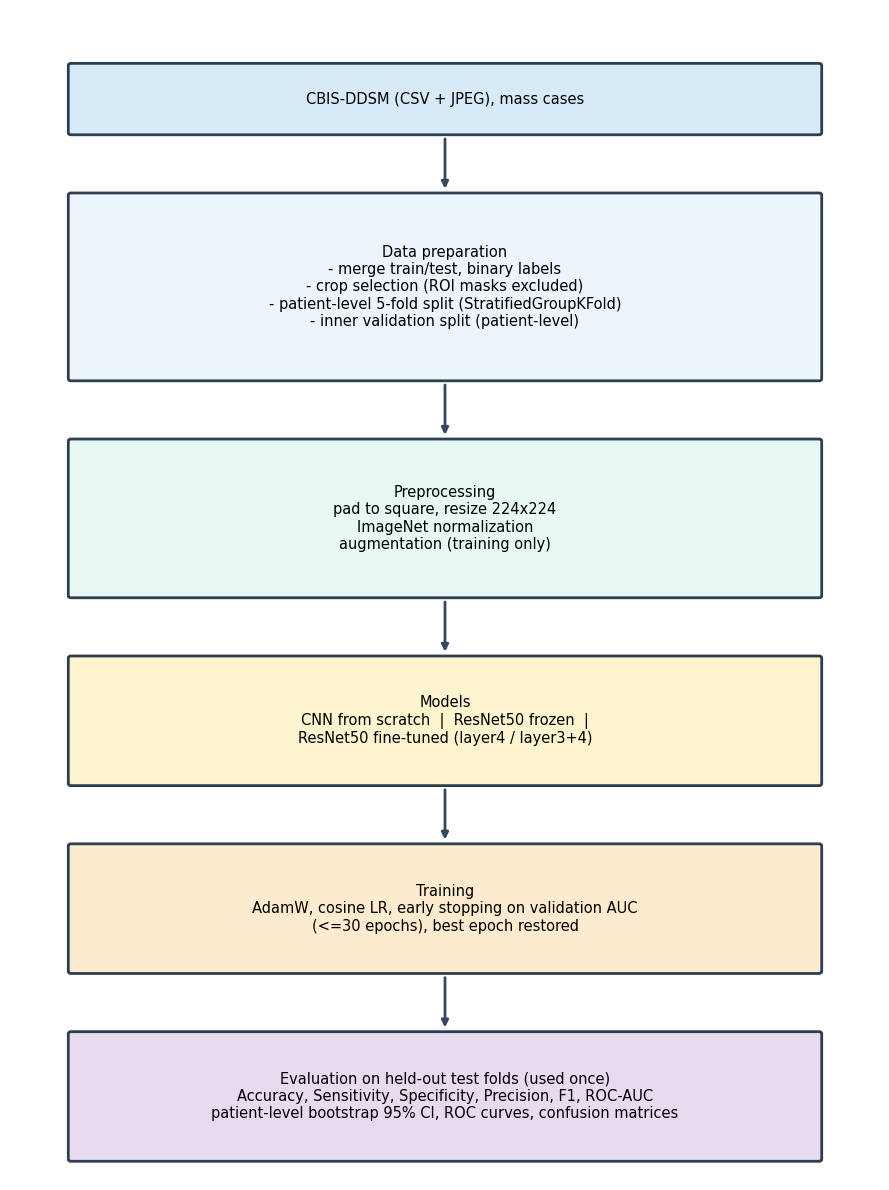

In [25]:
# Шаг 11. Обновлённая схема эксперимента (рис. 2) -- должна соответствовать новому протоколу
from matplotlib.patches import FancyBboxPatch
stages = [
    ("CBIS-DDSM (CSV + JPEG), mass cases", "#D6EAF8"),
    ("Data preparation\n- merge train/test, binary labels\n- crop selection (ROI masks excluded)\n"
     "- patient-level 5-fold split (StratifiedGroupKFold)\n"
     "- inner validation split (patient-level)", "#EBF5FB"),
    ("Preprocessing\npad to square, resize 224x224\nImageNet normalization\n"
     "augmentation (training only)", "#E8F8F5"),
    ("Models\nCNN from scratch  |  ResNet50 frozen  |\nResNet50 fine-tuned (layer4 / layer3+4)", "#FCF3CF"),
    ("Training\nAdamW, cosine LR, early stopping on validation AUC\n"
     "(<=30 epochs), best epoch restored", "#FDEBD0"),
    ("Evaluation on held-out test folds (used once)\n"
     "Accuracy, Sensitivity, Specificity, Precision, F1, ROC-AUC\n"
     "patient-level bootstrap 95% CI, ROC curves, confusion matrices", "#E8DAEF"),
]
fig, ax = plt.subplots(figsize=(9, 12)); ax.set_xlim(0, 10); ax.axis("off")
y_cur, gap = 0.0, 0.9
pos = []
for text, col in stages:
    h = 0.55 + 0.42 * (text.count("\n") + 1)
    pos.append((y_cur - h / 2, h)); y_cur -= h + gap
ax.set_ylim(y_cur + gap - 0.3, 0.8)
for (yc, h), (text, col) in zip(pos, stages):
    ax.add_patch(FancyBboxPatch((0.7, yc - h / 2), 8.6, h, boxstyle="round,pad=0.03",
                                lw=2, ec="#2C3E50", fc=col))
    ax.text(5, yc, text, ha="center", va="center", fontsize=10.5)
for (y1, h1), (y2, h2) in zip(pos[:-1], pos[1:]):
    ax.annotate("", xy=(5, y2 + h2 / 2 + 0.05), xytext=(5, y1 - h1 / 2 - 0.05),
                arrowprops=dict(arrowstyle="-|>", lw=2, color="#34495E"))
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/fig_pipeline_v2.png", dpi=600, bbox_inches="tight"); plt.show()

Новые проверки

In [26]:
# Контроль: насколько предсказывает метку один лишь размер/форма кропа (без пикселей)?
from sklearn.linear_model import LogisticRegression
feat = np.c_[np.log(df_all["orig_w"]), np.log(df_all["orig_h"]),
             np.log(df_all["orig_w"] / df_all["orig_h"])]
oof = np.zeros(len(df_all))
for f in FOLDS_PAT:
    tr = np.r_[f["train"], f["val"]]
    lr = LogisticRegression(max_iter=1000).fit(feat[tr], y_all[tr])
    oof[f["test"]] = lr.predict_proba(feat[f["test"]])[:, 1]
Ps = {"size": dict(prob=oof, pred_y=(oof >= 0.5).astype(int))}
Bs = cluster_boot(Ps, "pred_y", 1000)
print("AUC только по размеру/форме кропа:", fmt(roc_auc_score(y_all, oof), Bs["size"]["auc"]))


AUC только по размеру/форме кропа: 0.604 [0.568-0.645]


In [27]:
# Парные сравнения между экспериментами: одни и те же бутстреп-выборки пациентов
def paired(exp_a, exp_b, model, key="pred_y", n_boot=2000):
    P2 = {"a": pooled(exp_a, model, SEED0), "b": pooled(exp_b, model, SEED0)}
    Bt = cluster_boot(P2, key, n_boot)
    pa = metrics_from(y_all, P2["a"]["prob"], P2["a"][key])
    pb = metrics_from(y_all, P2["b"]["prob"], P2["b"][key])
    rows = []
    for k in ("acc", "auc"):
        d = Bt["a"][k] - Bt["b"][k]
        lo, hi = np.percentile(d, [2.5, 97.5])
        rows.append(dict(comparison=f"{exp_a} - {exp_b}", model=LABEL[model], metric=k,
                         diff=f"{pa[k] - pb[k]:+.3f}", ci95=f"[{lo:+.3f}, {hi:+.3f}]"))
    return rows

rows = []
for m in E2_MODELS:
    rows += paired("E3", "E1", m)          # утечка: разбиение по записям минус по пациентам
    rows += paired("E1", "E2_n0a0", m)     # полная предобработка минус её отсутствие
tab_pe = pd.DataFrame(rows)
tab_pe.to_csv(f"{TAB_DIR}/table_paired_E2_E3.csv", index=False)
print(tab_pe.to_string(index=False))


  comparison                model metric   diff             ci95
     E3 - E1    ResNet50 (frozen)    acc +0.003 [-0.012, +0.019]
     E3 - E1    ResNet50 (frozen)    auc -0.000 [-0.007, +0.007]
E1 - E2_n0a0    ResNet50 (frozen)    acc +0.006 [-0.018, +0.031]
E1 - E2_n0a0    ResNet50 (frozen)    auc -0.003 [-0.024, +0.018]
     E3 - E1 ResNet50 (FT layer4)    acc +0.006 [-0.012, +0.026]
     E3 - E1 ResNet50 (FT layer4)    auc +0.017 [-0.001, +0.036]
E1 - E2_n0a0 ResNet50 (FT layer4)    acc +0.012 [-0.013, +0.037]
E1 - E2_n0a0 ResNet50 (FT layer4)    auc +0.003 [-0.018, +0.024]


In [28]:
# Контроль: замороженный backbone обучался до лимита эпох -- даём ему 60 эпох
C["MAX_EPOCHS"] = 60
run_grid("E1L", ["resnet_frozen"], use_norm=True, use_aug=True, split_mode="patient")
C["MAX_EPOCHS"] = 30
PL = {"frozen_30": pooled("E1", "resnet_frozen", SEED0),
      "frozen_60": pooled("E1L", "resnet_frozen", SEED0),
      "ft_l4": pooled("E1", "resnet_ft_l4", SEED0)}
BL = cluster_boot(PL, "pred_y", 1000)
pt = {k: metrics_from(y_all, PL[k]["prob"], PL[k]["pred_y"]) for k in PL}
for k in PL:
    print(f"{k:10s} AUC {fmt(pt[k]['auc'], BL[k]['auc'])} | acc {fmt(pt[k]['acc'], BL[k]['acc'])}")
for k in ("auc", "acc"):
    d = BL["ft_l4"][k] - BL["frozen_60"][k]
    lo, hi = np.percentile(d, [2.5, 97.5])
    print(f"FT layer4 - frozen_60, {k}: {pt['ft_l4'][k] - pt['frozen_60'][k]:+.3f} [{lo:+.3f}, {hi:+.3f}]")


E1L | resnet_frozen | fold 0 | seed 0 | эпох 33 (лучшая 26) | val AUC 0.807 | test acc@0.5 0.673 | test AUC 0.751 | 2.2 мин
E1L | resnet_frozen | fold 1 | seed 0 | эпох 30 (лучшая 23) | val AUC 0.753 | test acc@0.5 0.675 | test AUC 0.755 | 2.0 мин
E1L | resnet_frozen | fold 2 | seed 0 | эпох 48 (лучшая 41) | val AUC 0.751 | test acc@0.5 0.771 | test AUC 0.824 | 3.2 мин
E1L | resnet_frozen | fold 3 | seed 0 | эпох 45 (лучшая 38) | val AUC 0.760 | test acc@0.5 0.718 | test AUC 0.795 | 3.1 мин
E1L | resnet_frozen | fold 4 | seed 0 | эпох 34 (лучшая 27) | val AUC 0.778 | test acc@0.5 0.629 | test AUC 0.693 | 2.3 мин
frozen_30  AUC 0.760 [0.732-0.788] | acc 0.699 [0.673-0.726]
frozen_60  AUC 0.753 [0.724-0.781] | acc 0.697 [0.671-0.722]
ft_l4      AUC 0.785 [0.760-0.809] | acc 0.731 [0.708-0.753]
FT layer4 - frozen_60, auc: +0.032 [+0.010, +0.055]
FT layer4 - frozen_60, acc: +0.034 [+0.012, +0.057]


In [29]:
# Контроль формы кропа: вместо чёрных полей кроп растягивается до квадрата (как в исходной версии)
def load_stretch(path, size):
    im = Image.open(path).convert("L").resize((size, size), Image.BILINEAR)
    return np.asarray(im, dtype=np.uint8)

X_pad = X
X_str = np.stack([load_stretch(p, C["IMG_SIZE"]) for p in tqdm(df_all["image_path"])])
X = X_str                                   # train_one_run читает глобальную переменную X
run_grid("E5_stretch", ["resnet_frozen", "resnet_ft_l4"], use_norm=True, use_aug=True,
         split_mode="patient")
X = X_pad                                   # возвращаем данные с чёрными полями

rows = []
for m in ["resnet_frozen", "resnet_ft_l4"]:
    Pp = {"pad": pooled("E1", m, SEED0), "stretch": pooled("E5_stretch", m, SEED0)}
    Bq = cluster_boot(Pp, "pred_y", 1000)
    pt = {k: metrics_from(y_all, Pp[k]["prob"], Pp[k]["pred_y"]) for k in Pp}
    d = Bq["pad"]["auc"] - Bq["stretch"]["auc"]
    lo, hi = np.percentile(d, [2.5, 97.5])
    rows.append(dict(model=LABEL[m], auc_pad=fmt(pt["pad"]["auc"], Bq["pad"]["auc"]),
                     auc_stretch=fmt(pt["stretch"]["auc"], Bq["stretch"]["auc"]),
                     diff_auc=f"{pt['pad']['auc'] - pt['stretch']['auc']:+.3f} [{lo:+.3f}, {hi:+.3f}]"))
tab_str = pd.DataFrame(rows)
tab_str.to_csv(f"{TAB_DIR}/table_pad_vs_stretch.csv", index=False)
print(tab_str.to_string(index=False))


  0%|          | 0/1696 [00:00<?, ?it/s]

E5_stretch | resnet_frozen | fold 0 | seed 0 | эпох 21 (лучшая 14) | val AUC 0.795 | test acc@0.5 0.690 | test AUC 0.740 | 1.4 мин
E5_stretch | resnet_frozen | fold 1 | seed 0 | эпох 16 (лучшая  9) | val AUC 0.743 | test acc@0.5 0.670 | test AUC 0.712 | 1.1 мин
E5_stretch | resnet_frozen | fold 2 | seed 0 | эпох 30 (лучшая 29) | val AUC 0.709 | test acc@0.5 0.760 | test AUC 0.818 | 2.0 мин
E5_stretch | resnet_frozen | fold 3 | seed 0 | эпох 30 (лучшая 24) | val AUC 0.733 | test acc@0.5 0.715 | test AUC 0.768 | 2.1 мин
E5_stretch | resnet_frozen | fold 4 | seed 0 | эпох 23 (лучшая 16) | val AUC 0.772 | test acc@0.5 0.620 | test AUC 0.709 | 1.6 мин
E5_stretch | resnet_ft_l4  | fold 0 | seed 0 | эпох 21 (лучшая 14) | val AUC 0.850 | test acc@0.5 0.707 | test AUC 0.769 | 1.5 мин
E5_stretch | resnet_ft_l4  | fold 1 | seed 0 | эпох 10 (лучшая  3) | val AUC 0.799 | test acc@0.5 0.609 | test AUC 0.762 | 0.7 мин
E5_stretch | resnet_ft_l4  | fold 2 | seed 0 | эпох 15 (лучшая  8) | val AUC 0.777 

In [30]:
# Повторы инициализации: ResNet frozen и FT layer4 с seed 0, 1, 2 (seed 0 берётся из кэша)
C["TRAIN_SEEDS"] = [0, 1, 2]
SEED_MODELS = ["resnet_frozen", "resnet_ft_l4"]
run_grid("E1", SEED_MODELS, use_norm=True, use_aug=True, split_mode="patient")
rows = []
for s in C["TRAIN_SEEDS"]:
    a = {m: metrics_from(y_all, pooled("E1", m, s)["prob"], pooled("E1", m, s)["pred_y"])
         for m in SEED_MODELS}
    rows.append(dict(seed=s, auc_frozen=a["resnet_frozen"]["auc"], auc_ft_l4=a["resnet_ft_l4"]["auc"],
                     d_auc=a["resnet_ft_l4"]["auc"] - a["resnet_frozen"]["auc"],
                     acc_frozen=a["resnet_frozen"]["acc"], acc_ft_l4=a["resnet_ft_l4"]["acc"],
                     d_acc=a["resnet_ft_l4"]["acc"] - a["resnet_frozen"]["acc"]))
tab_seeds = pd.DataFrame(rows)
tab_seeds.to_csv(f"{TAB_DIR}/table_seeds_frozen_vs_ft.csv", index=False)
print(tab_seeds.round(3).to_string(index=False))
print(tab_seeds.drop(columns="seed").agg(["mean", "std"]).round(3))


E1 | resnet_frozen | fold 0 | seed 0 | эпох 30 (лучшая 27) | val AUC 0.803 | test acc@0.5 0.699 | test AUC 0.744 | 2.0 мин
E1 | resnet_frozen | fold 0 | seed 1 | эпох 30 (лучшая 30) | val AUC 0.804 | test acc@0.5 0.704 | test AUC 0.746 | 2.1 мин
E1 | resnet_frozen | fold 0 | seed 2 | эпох 30 (лучшая 24) | val AUC 0.802 | test acc@0.5 0.696 | test AUC 0.743 | 2.0 мин
E1 | resnet_frozen | fold 1 | seed 0 | эпох 30 (лучшая 30) | val AUC 0.749 | test acc@0.5 0.681 | test AUC 0.751 | 2.0 мин
E1 | resnet_frozen | fold 1 | seed 1 | эпох 26 (лучшая 19) | val AUC 0.751 | test acc@0.5 0.667 | test AUC 0.751 | 1.8 мин
E1 | resnet_frozen | fold 1 | seed 2 | эпох 30 (лучшая 25) | val AUC 0.753 | test acc@0.5 0.687 | test AUC 0.751 | 2.1 мин
E1 | resnet_frozen | fold 2 | seed 0 | эпох 30 (лучшая 29) | val AUC 0.720 | test acc@0.5 0.755 | test AUC 0.817 | 2.0 мин
E1 | resnet_frozen | fold 2 | seed 1 | эпох 30 (лучшая 26) | val AUC 0.735 | test acc@0.5 0.771 | test AUC 0.820 | 2.1 мин
E1 | resnet_froz